In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex

#import csv

import numpy as np

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.analysis import Resample_Equidistant
from scientific_utils.battery.plotting import Matplotlib_Compare_Raw_And_Equidistant_Data
from scientific_utils.battery.plotting import Matplotlib_Overview_With_Colormap
from scientific_utils.general.plotting import Convert_cm_To_inch

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the .pkl file ########
########## Open the CP steps
########## save the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_CP_charge_cycling.pkl', 'rb') as f:
    list_of_dataframes_CP_charge_cycling = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_CP_discharge_cycling.pkl', 'rb') as f:
    list_of_dataframes_CP_discharge_cycling = pickle.load(f) 


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
################################ CHARGE CURVES ##########################################

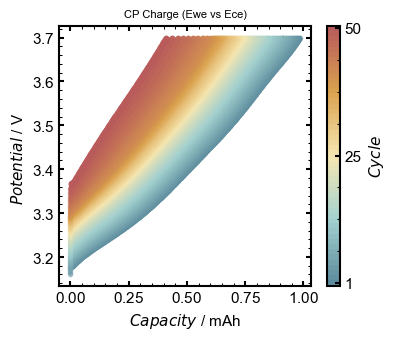

In [9]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_CP_charge_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r'$Potential$ / V  '
x_ax_label = r'$Capacity$ / mAh '
save = -1 
name_figure = 'CP_Charge_Ewe_vs_Ece'
legend_title = 'CP Charge (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

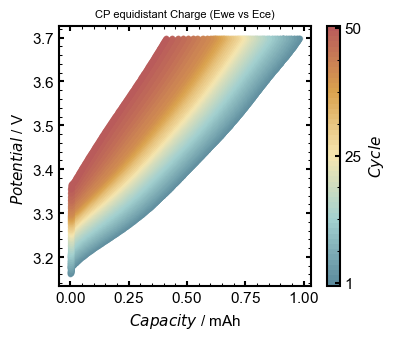

In [10]:
# equidistancing the data
list_of_dataframes = list_of_dataframes_CP_charge_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'

list_of_dataframes_of_CP_charge_equidistant_cycling = Resample_Equidistant(list_of_dataframes, x_values_column_name, y_values_column_name)

# Plotting of the equidistant Charging curves with the above definened function
list_of_dataframes = list_of_dataframes_of_CP_charge_equidistant_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r'$Potential$ / V  '
x_ax_label = r'$Capacity$ / mAh '
save = -1 
name_figure = 'CP_equidistant_Charge_Ewe_vs_Ece'
legend_title = 'CP equidistant Charge (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

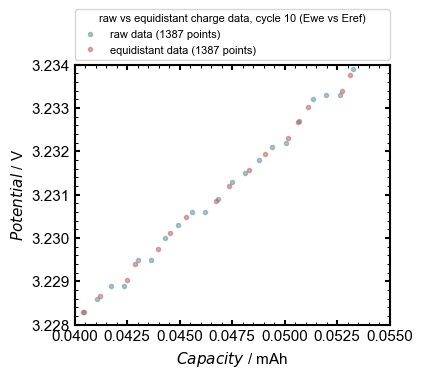

In [11]:
# Plot a comparison between raw and equidistant data
# defining the arguments for the function
dataframe = list_of_dataframes_CP_charge_cycling[9]
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
cycle = 'Cycle 10'
dataframe_equidistant = list_of_dataframes_of_CP_charge_equidistant_cycling[9]
x_values_column_name_equidistant = 'Capacity (mAh)'
y_values_column_name_equidistant = 'Voltage (V)'
y_ax_label = r'$Potential$ / V'
y_ax_lim = 3.228, 3.234
x_ax_label = r'$Capacity$ / mAh'
x_ax_lim = 0.04, 0.055
save = -1 
name_figure = 'raw_charge_data_vs_equidistant_charge_data_for_Cycle_Ewe_vs_Eref'
legend_title = 'raw vs equidistant charge data, cycle 10 (Ewe vs Eref)'
# plotting with function
Matplotlib_Compare_Raw_And_Equidistant_Data(dataframe, x_values_column_name, y_values_column_name, cycle, dataframe_equidistant, x_values_column_name_equidistant, y_values_column_name_equidistant ,y_ax_label, y_ax_lim, x_ax_label, x_ax_lim, save, name_figure, legend_title)

In [12]:
################################# DISCHARGE CURVE ######################################

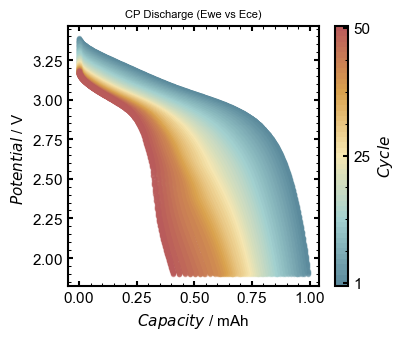

In [13]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_CP_discharge_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r'$Potential$ / V  '
x_ax_label = r'$Capacity$ / mAh '
save = -1 
name_figure = 'CP_Discharge_Ewe_vs_Ece'
legend_title = 'CP Discharge (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

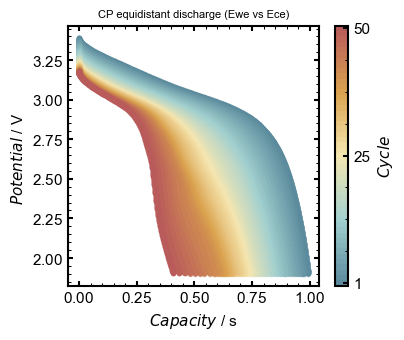

In [14]:
# equidistancing the data
list_of_dataframes = list_of_dataframes_CP_discharge_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'

list_of_dataframes_of_CP_discharge_equidistant_cycling = Resample_Equidistant(list_of_dataframes, x_values_column_name, y_values_column_name)

# Plotting of the equidistant Charging curves with the above definened function
list_of_dataframes = list_of_dataframes_of_CP_discharge_equidistant_cycling
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
y_ax_label = r'$Potential$ / V  '
x_ax_label = r'$Capacity$ / s '
save = -1 
name_figure = 'CP_equidistant_Discharge_Ewe_vs_Ece'
legend_title = 'CP equidistant discharge (Ewe vs Ece)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

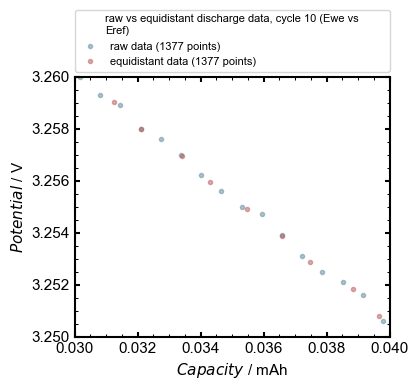

In [15]:
# Plot a comparison between raw and equidistant data
# defining the arguments for the function
dataframe = list_of_dataframes_CP_discharge_cycling[9]
x_values_column_name = 'Capacity (mAh)'
y_values_column_name = 'Voltage (V)'
cycle = 'Cycle 10'
dataframe_equidistant = list_of_dataframes_of_CP_discharge_equidistant_cycling[9]
x_values_column_name_equidistant = 'Capacity (mAh)'
y_values_column_name_equidistant = 'Voltage (V)'
y_ax_label = r'$Potential$ / V'
y_ax_lim = 3.25, 3.26
x_ax_label = r'$Capacity$ / mAh'
x_ax_lim = 0.03, 0.04
save = -1 
name_figure = 'raw_charge_data_vs_equidistant_discharge_data_for_Cycle_Ewe_vs_Eref'
legend_title = 'raw vs equidistant discharge data, cycle 10 (Ewe vs Eref)'
# plotting with function
Matplotlib_Compare_Raw_And_Equidistant_Data(dataframe, x_values_column_name, y_values_column_name, cycle, dataframe_equidistant, x_values_column_name_equidistant, y_values_column_name_equidistant ,y_ax_label, y_ax_lim, x_ax_label, x_ax_lim, save, name_figure, legend_title)

In [16]:
########## Save the data as .pkl ##########
##### Charge Curves
with open('../data/Batt15/processed/list_of_dataframes_of_CP_charge_equidistant_cycling.pkl', 'wb') as f:
    pickle.dump(list_of_dataframes_of_CP_charge_equidistant_cycling, f)
##### Discharge Curves
with open('../data/Batt15/processed/list_of_dataframes_of_CP_discharge_equidistant_cycling.pkl', 'wb') as f:
    pickle.dump(list_of_dataframes_of_CP_discharge_equidistant_cycling, f)    